# Classification Models

## Discussion questions

Suppose you are developing a classification model to determine whether or not a person has a particular disease (based on symptoms, results of diagnostic tests, family history, risk factors, etc).

1. Explain what "precision" represents in this context.

**Discuss with your partner, and make notes here.**

2. Explain what "recall" represents in this context.

**Discuss with your partner, and make notes here.**

3. Which of the following do you think is a more serious error? It's an opinion question, but choose one and discuss.

- Concluding that a person has the disease if they actually don't have it
- Failing to conclude that a person has the disease if they actually do have it

**Discuss with your partner, and make notes here.**

4. Given your answer to the previous question, which would you prefer to be higher: precision or recall?

**Discuss with your partner, and make notes here.**

5. Suppose you want to achieve higher recall. Should your classification rule be more or less strict about who it predicts to have the disease?

**Discuss with your partner, and make notes here.**

6. What is a downside to your choice in the previous part?

**Discuss with your partner, and make notes here.**

In [1]:
import pandas as pd
import numpy as np

## More wine

The wines data set (https://dlsun.github.io/pods/data/wines.csv ) contains data about the chemical composition of various wines. We'll first use just two features&mdash;fixed acidity and volatile acidity&mdash;to predict the color of the wine (red or white).

In [2]:
df_train = pd.read_csv("https://dlsun.github.io/pods/data/wines.csv")

df_train

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white


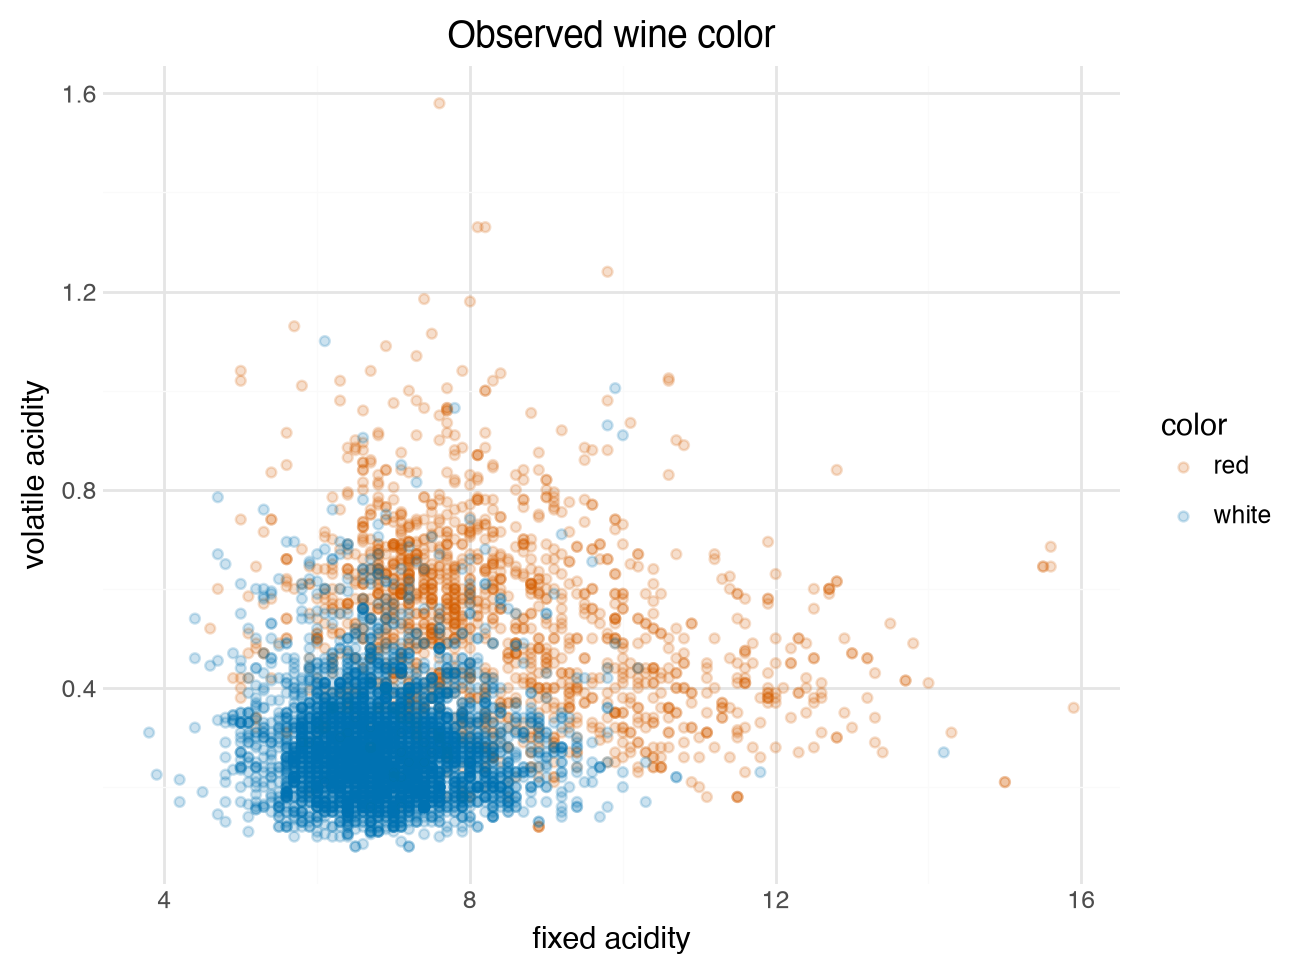

In [3]:
from plotnine import *

(
    ggplot(df_train, aes(x="fixed acidity", y="volatile acidity", color="color"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Observed wine color")
    + theme_minimal()
)

1\. Fit a 15-nearest neighbors model for predicting color from fixed acidity and volatile acidity. Don't forget to scale the features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the observed colors.

In [5]:
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, precision_recall_curve, roc_curve, roc_auc_score,
                             average_precision_score, log_loss)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier

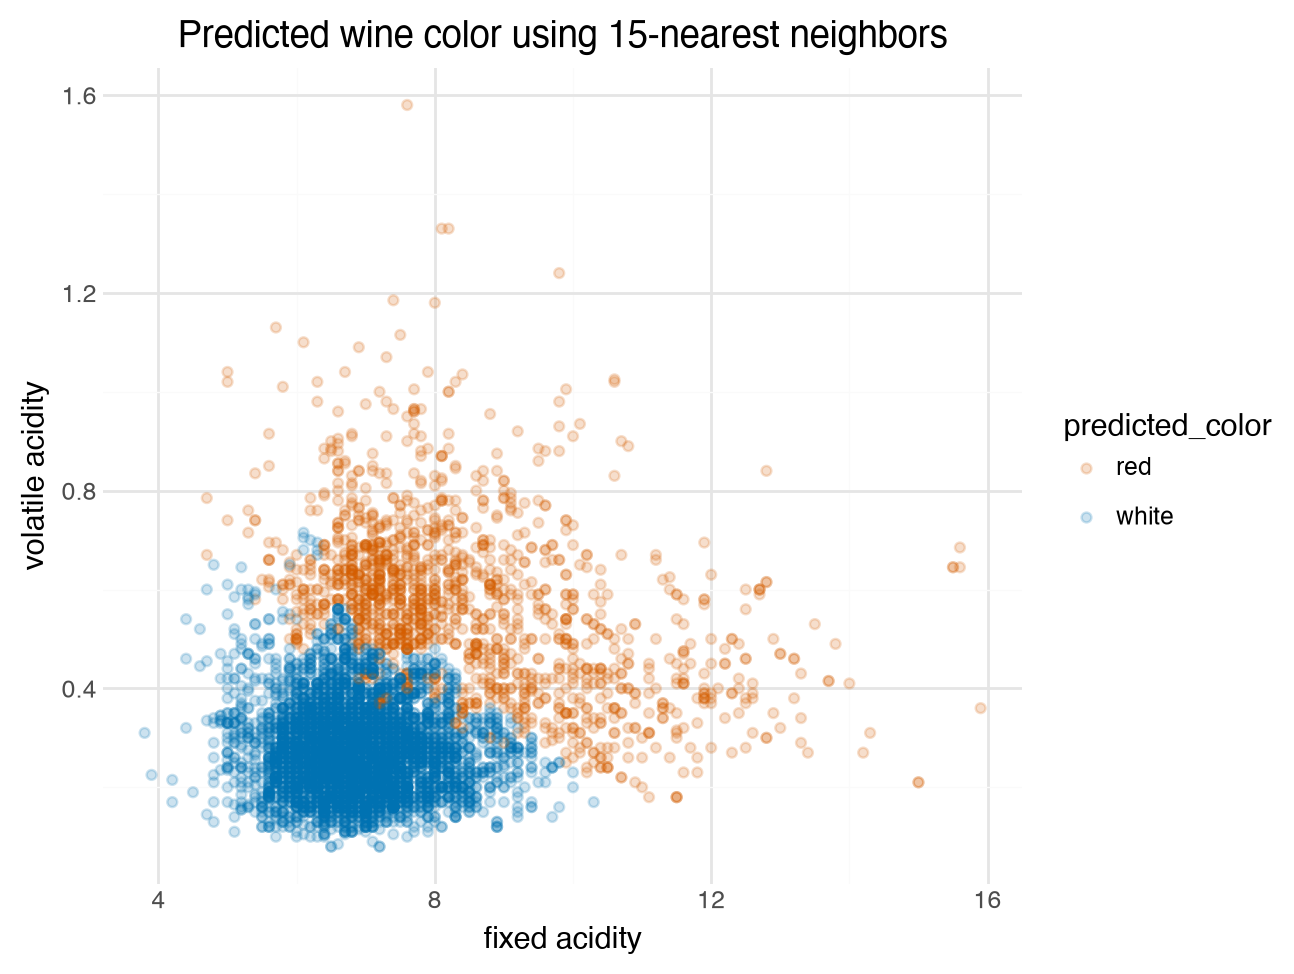

In [6]:
# YOUR CODE HERE
X_train = df_train[["fixed acidity", "volatile acidity"]]
y_train = df_train["color"]

knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=15)
)

knn_model.fit(X_train, y_train)

df_train["predicted_color"] = knn_model.predict(X_train)

(
    ggplot(
        df_train,
        aes(x="fixed acidity", y="volatile acidity", color="predicted_color")
    )
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Predicted wine color using 15-nearest neighbors")
    + theme_minimal()
)

2\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score using `macro` scoring.

In [7]:
# YOUR CODE HERE
from sklearn.model_selection import cross_val_score

precision = cross_val_score(
    knn_model, X_train, y_train, cv=10, scoring="precision_macro"
).mean()

recall = cross_val_score(
    knn_model, X_train, y_train, cv=10, scoring="recall_macro"
).mean()

f1 = cross_val_score(
    knn_model, X_train, y_train, cv=10, scoring="f1_macro"
).mean()

pd.Series({
    "Precision": precision,
    "Recall": recall,
    "F1 score": f1
})

Precision    0.881381
Recall       0.854369
F1 score     0.863297
dtype: float64

3\. Use `GridSearchCV` to fit $k$-nearest neighbors models for $k=1,\ldots, 30$ and use cross validation to estimate the test F1 macro score. Plot the test score versus $k$. Which value of $k$ yields the best score?

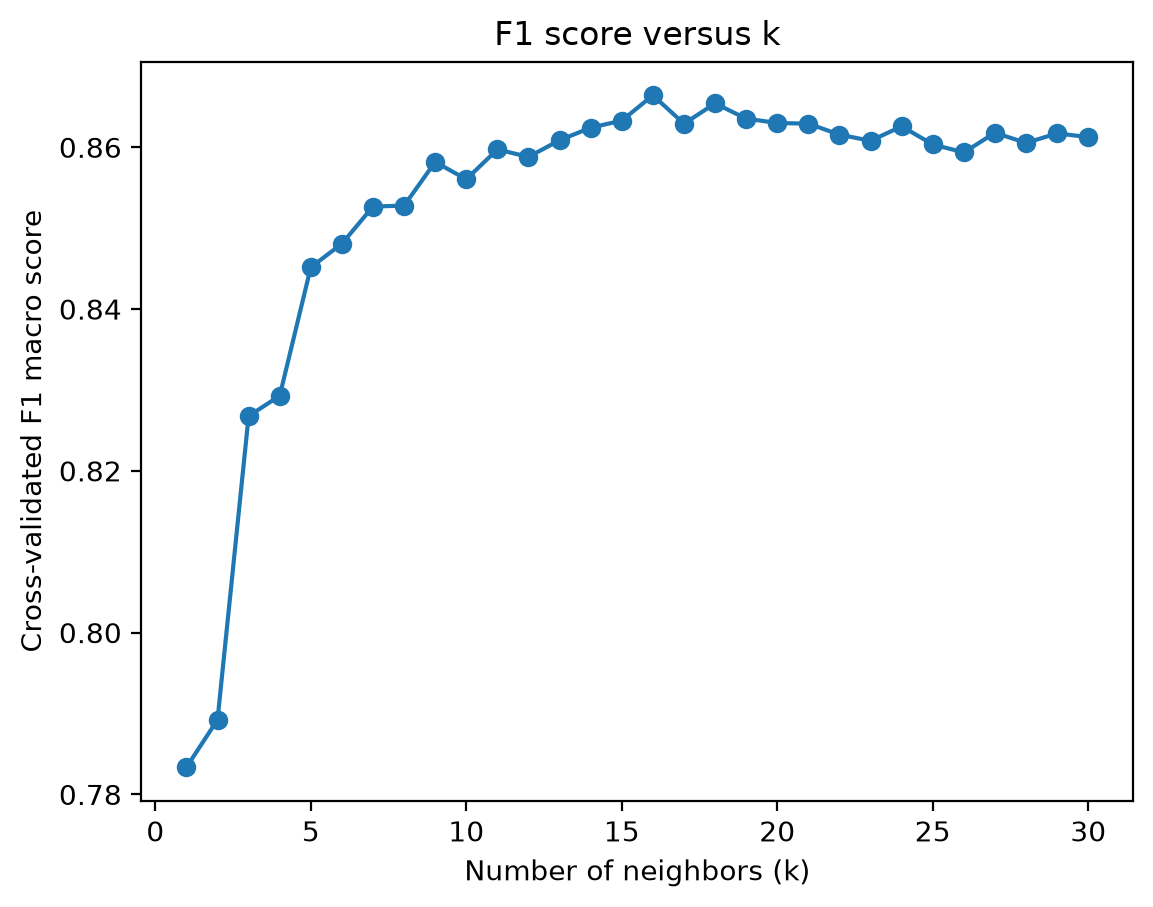

Best k: 16
Best F1 score: 0.8664272356440673


In [8]:
# YOUR CODE HERE
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    knn_model,
    {"kneighborsclassifier__n_neighbors": range(1, 31)},
    cv=10,
    scoring="f1_macro"
)

grid.fit(X_train, y_train)

results = pd.DataFrame(grid.cv_results_)

plt.plot(
    results["param_kneighborsclassifier__n_neighbors"],
    results["mean_test_score"],
    marker="o"
)

plt.xlabel("Number of neighbors (k)")
plt.ylabel("Cross-validated F1 macro score")
plt.title("F1 score versus k")
plt.show()

print("Best k:", grid.best_params_["kneighborsclassifier__n_neighbors"])
print("Best F1 score:", grid.best_score_)

4\. When the target variable is binary **logistic regression** provides another classification algorithm.

Fit a logistic regression model for predicting wine color from the two features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the predictions from the nearest neighbors classifier.

Note: with regression, you don't need to scale the features (unless you add a penalty). Hint: you basically just need to replace with `KNeighborsClassifier()` with `LogisticRegression()`.

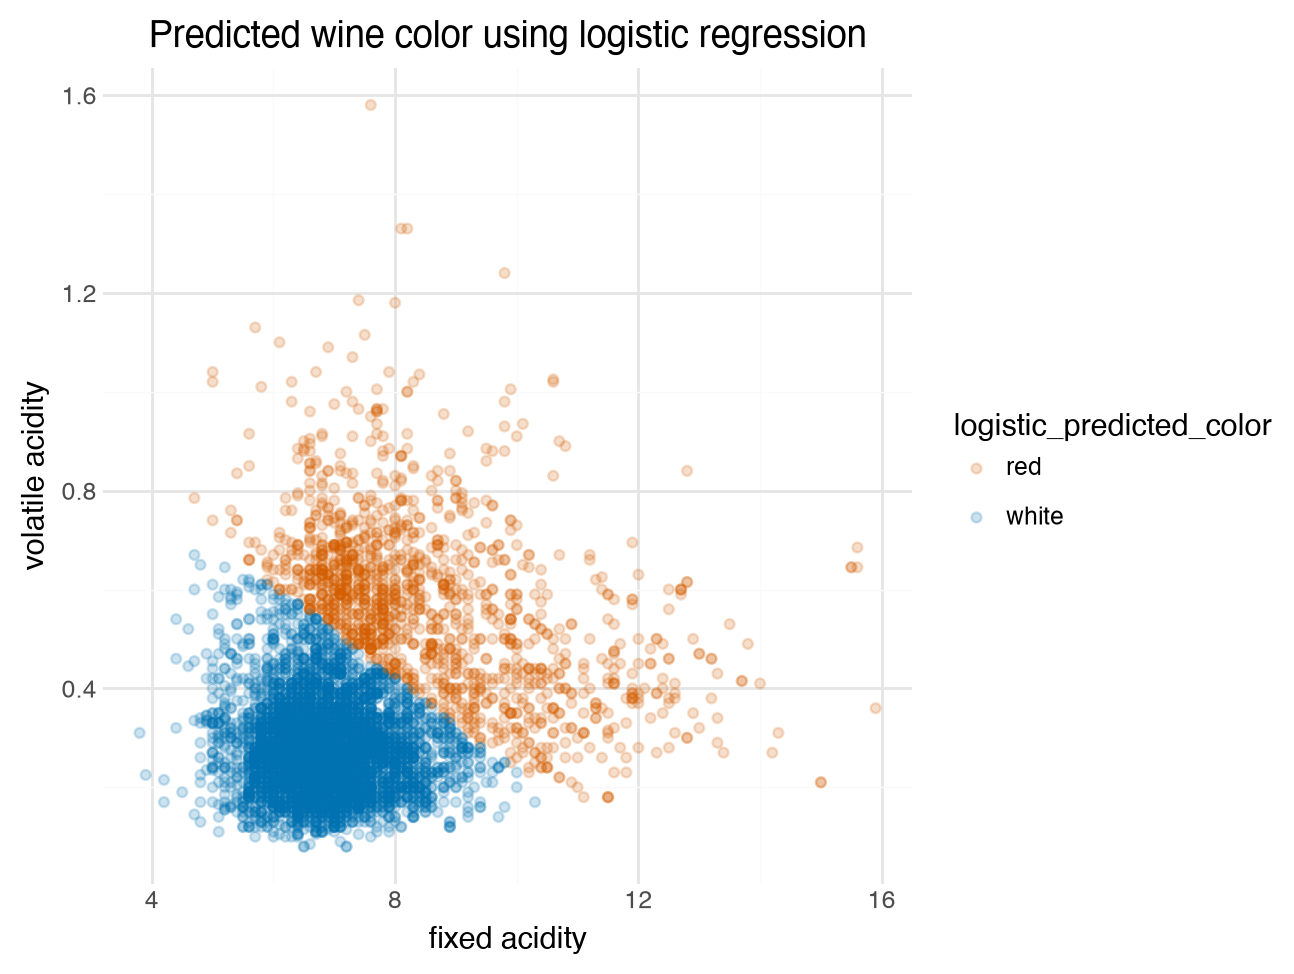

In [9]:
from sklearn.linear_model import LogisticRegression

# YOUR CODE HERE
logistic_model = LogisticRegression()
logistic_model.fit(X_train, y_train)

df_train["logistic_predicted_color"] = logistic_model.predict(X_train)

(
    ggplot(
        df_train,
        aes(
            x="fixed acidity",
            y="volatile acidity",
            color="logistic_predicted_color"
        )
    )
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Predicted wine color using logistic regression")
    + theme_minimal()
)

The logistic regression predictions have a smoother, more linear boundary between red and white wines. The nearest-neighbors model produces a more irregular boundary because its predictions depend on nearby observations.

5\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring. Compare to the nearest neighbors model.

In [10]:
# YOUR CODE HERE
logistic_precision = cross_val_score(
    logistic_model, X_train, y_train, cv=10, scoring="precision_macro"
).mean()

logistic_recall = cross_val_score(
    logistic_model, X_train, y_train, cv=10, scoring="recall_macro"
).mean()

logistic_f1 = cross_val_score(
    logistic_model, X_train, y_train, cv=10, scoring="f1_macro"
).mean()

pd.DataFrame({
    "KNN": [precision, recall, f1],
    "Logistic regression": [
        logistic_precision,
        logistic_recall,
        logistic_f1
    ]
}, index=["Precision", "Recall", "F1 score"])

,KNN,Logistic regression
Precision,0.881381,0.892620
Recall,0.854369,0.845064
F1 score,0.863297,0.860420


6\. Now fit a logistic regression model using all of the potential predictors. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [12]:
# YOUR CODE HERE
X_all = df_train.select_dtypes(include="number")
y_all = df_train["color"]

logistic_all = LogisticRegression(max_iter=5000)

all_precision = cross_val_score(
    logistic_all, X_all, y_all, cv=10, scoring="precision_macro"
).mean()

all_recall = cross_val_score(
    logistic_all, X_all, y_all, cv=10, scoring="recall_macro"
).mean()

all_f1 = cross_val_score(
    logistic_all, X_all, y_all, cv=10, scoring="f1_macro"
).mean()

pd.Series({
    "Precision": all_precision,
    "Recall": all_recall,
    "F1 score": all_f1
})

Precision    0.984043
Recall       0.976081
F1 score     0.979865
dtype: float64

7\. Now fit a logistic regression model using all of the potential predictors with a LASSO (`"l1"`) penalty. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [13]:
# YOUR CODE HERE
lasso_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l1",
        solver="saga",
        max_iter=10000,
        random_state=0
    )
)

lasso_precision = cross_val_score(
    lasso_model, X_all, y_all, cv=10, scoring="precision_macro"
).mean()

lasso_recall = cross_val_score(
    lasso_model, X_all, y_all, cv=10, scoring="recall_macro"
).mean()

lasso_f1 = cross_val_score(
    lasso_model, X_all, y_all, cv=10, scoring="f1_macro"
).mean()

pd.Series({
    "Precision": lasso_precision,
    "Recall": lasso_recall,
    "F1 score": lasso_f1
})

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_rat

Precision    0.992048
Recall       0.990136
F1 score     0.991058
dtype: float64